# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [ ]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.019s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.019s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12.1


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [ ]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Writing Hello.java


In [ ]:
!java Hello.java

---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [1]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Writing TariffBefore.java


In [2]:
!java TariffBefore.java

[0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.021s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [3]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Writing TariffAfter.java


In [4]:
!java TariffAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [10]:
!apt-get update -qq
!apt-get install -y plantuml graphviz > /dev/null
print("PlantUML и GraphViz установлены")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
PlantUML и GraphViz установлены


In [11]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


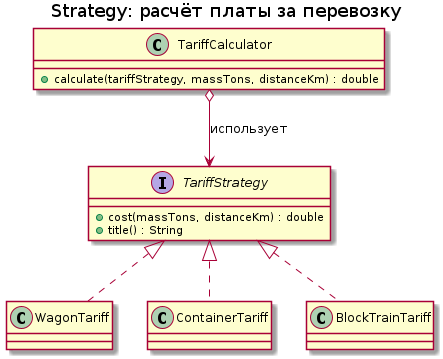

In [13]:
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** _(В коде «до» пришлось бы изменить метод cost (добавить еще один else if). В коде «после» достаточно создать новый класс RefrigeratedTariff, реализующий интерфейс TariffStrategy, и не трогать существующий код.)_
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** _(Метод legacyCost оставлен для характеризующих тестов, чтобы доказать, что новая система считает точно так же, как старая, и поведение не изменилось.)_
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** _(Если в каталоге нет нужного ключа, метод вернет null и произойдет NullPointerException. Это следует обработать, добавив проверку на null и выбрасывая понятное исключение (например, IllegalArgumentException).)_

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [14]:
%%writefile FactoryAfter.java
// 3.3 Реализация Factory Method
public class FactoryAfter {
    private static int failedChecks = 0;

    public static void main(String[] args) {
        WagonCreator coveredCreator = new CoveredWagonCreator();
        WagonCreator platformCreator = new PlatformCreator();
        WagonCreator tankCreator = new TankWagonCreator();

        // 4-й тип добавляем без правки остальных классов
        WagonCreator hopperCreator = new HopperWagonCreator();

        Wagon wagon1 = coveredCreator.createWagon(68);
        Wagon wagon2 = platformCreator.createWagon(71);
        Wagon wagon3 = tankCreator.createWagon(66);
        Wagon wagon4 = hopperCreator.createWagon(70);

        check("описание крытого", wagon1.description().contains("Крытый") && wagon1.description().contains("68"));
        check("описание платформы", wagon2.description().contains("Платформа") && wagon2.description().contains("71"));
        check("описание цистерны", wagon3.description().contains("Цистерна") && wagon3.description().contains("66"));
        check("тип объекта соответствует создателю", wagon1 instanceof CoveredWagon && wagon4 instanceof HopperWagon);
        check("четвертый тип работает", wagon4.description().contains("Зерновоз") && wagon4.description().contains("70"));

        if (failedChecks > 0) throw new AssertionError("не пройдено: " + failedChecks);
        System.out.println("Все проверки пройдены.");
    }

    static void check(String name, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + name);
        if (!passed) failedChecks++;
    }
}

// --- Участники паттерна ---
interface Wagon {
    String description();
    double capacityTons();
}

interface WagonCreator {
    Wagon createWagon(double capacityTons);
}

class CoveredWagon implements Wagon {
    private double cap;
    public CoveredWagon(double cap) { this.cap = cap; }
    public String description() { return "Крытый вагон: грузоподъёмность " + cap + " т, тарные и штучные грузы"; }
    public double capacityTons() { return cap; }
}

class Platform implements Wagon {
    private double cap;
    public Platform(double cap) { this.cap = cap; }
    public String description() { return "Платформа: грузоподъёмность " + cap + " т, длинномерные и тяжеловесные грузы"; }
    public double capacityTons() { return cap; }
}

class TankWagon implements Wagon {
    private double cap;
    public TankWagon(double cap) { this.cap = cap; }
    public String description() { return "Цистерна: грузоподъёмность " + cap + " т, наливные грузы"; }
    public double capacityTons() { return cap; }
}

// Новый 4-й тип
class HopperWagon implements Wagon {
    private double cap;
    public HopperWagon(double cap) { this.cap = cap; }
    public String description() { return "Зерновоз (Хоппер): грузоподъёмность " + cap + " т, сыпучие грузы"; }
    public double capacityTons() { return cap; }
}

class CoveredWagonCreator implements WagonCreator {
    public Wagon createWagon(double cap) { return new CoveredWagon(cap); }
}
class PlatformCreator implements WagonCreator {
    public Wagon createWagon(double cap) { return new Platform(cap); }
}
class TankWagonCreator implements WagonCreator {
    public Wagon createWagon(double cap) { return new TankWagon(cap); }
}
class HopperWagonCreator implements WagonCreator {
    public Wagon createWagon(double cap) { return new HopperWagon(cap); }
}

Overwriting FactoryAfter.java


In [9]:
!java FactoryBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Error: Could not find or load main class FactoryBefore.java
Caused by: java.lang.ClassNotFoundException: FactoryBefore.java


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [ ]:
%%writefile FactoryAfter.java
// 3.3 Ваша реализация Factory Method

In [ ]:
!java FactoryAfter.java

In [25]:
%%writefile factory.puml
@startuml
title Factory Method: создание вагона
interface Wagon
interface WagonCreator
class CoveredWagon implements Wagon
class Platform implements Wagon
class TankWagon implements Wagon
class HopperWagon implements Wagon
class CoveredWagonCreator implements WagonCreator
class PlatformCreator implements WagonCreator
class TankWagonCreator implements WagonCreator
class HopperWagonCreator implements WagonCreator
WagonCreator --> Wagon : создает >
@enduml

Overwriting factory.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


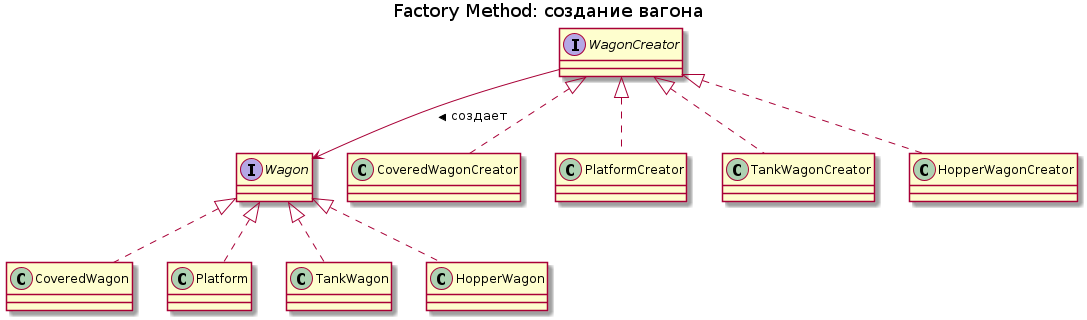

In [26]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): _(заполнить)_

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [ ]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

In [ ]:
!java ObserverBefore.java

### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [15]:
%%writefile ObserverAfter.java
%%writefile ObserverAfter.java
// 4.3 Реализация Observer
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {
    private static int failedChecks = 0;

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        Journal journal = new Journal();
        Board board = new Board();
        Mailing mailing = new Mailing();

        station.addListener(board);
        station.addListener(journal);
        station.addListener(mailing);

        station.trainArrived("3022");
        check("Журнал получил 1 запись", journal.getRecordsCount() == 1);
        check("Табло и рассылка тоже сработали", board.lastMessage != null && mailing.lastMessage != null);

        station.removeListener(journal);
        station.trainArrived("6701");
        check("После отписки журнал не пишет", journal.getRecordsCount() == 1);

        // 4-й наблюдатель
        AsuListener asu = new AsuListener();
        station.addListener(asu);
        station.trainArrived("9999");
        check("4-й наблюдатель работает", asu.received);

        if (failedChecks > 0) throw new AssertionError("не пройдено: " + failedChecks);
        System.out.println("Все проверки пройдены.");
    }

    static void check(String name, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + name);
        if (!passed) failedChecks++;
    }
}

// --- Участники паттерна ---
interface ArrivalListener {
    void onTrainArrived(String stationName, String trainNumber);
}

class Station {
    private String name;
    private List<ArrivalListener> listeners = new ArrayList<>();

    public Station(String name) { this.name = name; }
    public void addListener(ArrivalListener l) { listeners.add(l); }
    public void removeListener(ArrivalListener l) { listeners.remove(l); }

    public void trainArrived(String trainNumber) {
        for (ArrivalListener l : listeners) {
            l.onTrainArrived(name, trainNumber);
        }
    }
}

class Board implements ArrivalListener {
    public String lastMessage = null;
    public void onTrainArrived(String stationName, String trainNumber) {
        lastMessage = "[табло] Поезд " + trainNumber + " прибыл на " + stationName;
        System.out.println(lastMessage);
    }
}

class Journal implements ArrivalListener {
    private List<String> records = new ArrayList<>();
    public void onTrainArrived(String stationName, String trainNumber) {
        records.add(stationName + ":" + trainNumber);
        System.out.println("[журнал] Записано событие.");
    }
    public int getRecordsCount() { return records.size(); }
}

class Mailing implements ArrivalListener {
    public String lastMessage = null;
    public void onTrainArrived(String stationName, String trainNumber) {
        lastMessage = "Рассылка: поезд " + trainNumber;
        System.out.println("[рассылка] " + lastMessage);
    }
}

// 4-й наблюдатель
class AsuListener implements ArrivalListener {
    public boolean received = false;
    public void onTrainArrived(String stationName, String trainNumber) {
        received = true;
        System.out.println("[АСУ] Данные переданы в систему.");
    }
}

Writing ObserverAfter.java


In [17]:
%%writefile ObserverAfter.java
// 4.3 Реализация Observer
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {
    private static int failedChecks = 0;

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        Journal journal = new Journal();
        Board board = new Board();
        Mailing mailing = new Mailing();

        station.addListener(board);
        station.addListener(journal);
        station.addListener(mailing);

        station.trainArrived("3022");
        check("Журнал получил 1 запись", journal.getRecordsCount() == 1);
        check("Табло и рассылка тоже сработали", board.lastMessage != null && mailing.lastMessage != null);

        station.removeListener(journal);
        station.trainArrived("6701");
        check("После отписки журнал не пишет", journal.getRecordsCount() == 1);

        // 4-й наблюдатель
        AsuListener asu = new AsuListener();
        station.addListener(asu);
        station.trainArrived("9999");
        check("4-й наблюдатель работает", asu.received);

        if (failedChecks > 0) throw new AssertionError("не пройдено: " + failedChecks);
        System.out.println("Все проверки пройдены.");
    }

    static void check(String name, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + name);
        if (!passed) failedChecks++;
    }
}

// --- Участники паттерна ---
interface ArrivalListener {
    void onTrainArrived(String stationName, String trainNumber);
}

class Station {
    private String name;
    private List<ArrivalListener> listeners = new ArrayList<>();

    public Station(String name) { this.name = name; }
    public void addListener(ArrivalListener l) { listeners.add(l); }
    public void removeListener(ArrivalListener l) { listeners.remove(l); }

    public void trainArrived(String trainNumber) {
        for (ArrivalListener l : listeners) {
            l.onTrainArrived(name, trainNumber);
        }
    }
}

class Board implements ArrivalListener {
    public String lastMessage = null;
    public void onTrainArrived(String stationName, String trainNumber) {
        lastMessage = "[табло] Поезд " + trainNumber + " прибыл на " + stationName;
        System.out.println(lastMessage);
    }
}

class Journal implements ArrivalListener {
    private List<String> records = new ArrayList<>();
    public void onTrainArrived(String stationName, String trainNumber) {
        records.add(stationName + ":" + trainNumber);
        System.out.println("[журнал] Записано событие.");
    }
    public int getRecordsCount() { return records.size(); }
}

class Mailing implements ArrivalListener {
    public String lastMessage = null;
    public void onTrainArrived(String stationName, String trainNumber) {
        lastMessage = "Рассылка: поезд " + trainNumber;
        System.out.println("[рассылка] " + lastMessage);
    }
}

// 4-й наблюдатель
class AsuListener implements ArrivalListener {
    public boolean received = false;
    public void onTrainArrived(String stationName, String trainNumber) {
        received = true;
        System.out.println("[АСУ] Данные переданы в систему.");
    }
}

Overwriting ObserverAfter.java


In [18]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло] Поезд 3022 прибыл на Гомель
[журнал] Записано событие.
[рассылка] Рассылка: поезд 3022
[OK]   Журнал получил 1 запись
[OK]   Табло и рассылка тоже сработали
[табло] Поезд 6701 прибыл на Гомель
[рассылка] Рассылка: поезд 6701
[OK]   После отписки журнал не пишет
[табло] Поезд 9999 прибыл на Гомель
[рассылка] Рассылка: поезд 9999
[АСУ] Данные переданы в систему.
[OK]   4-й наблюдатель работает
Все проверки пройдены.


In [21]:
%%writefile observer.puml
@startuml
title Observer: оповещение о прибытии поезда
interface ArrivalListener
class Station {
  addListener()
  removeListener()
  trainArrived()
}
class Board implements ArrivalListener
class Journal implements ArrivalListener
class Mailing implements ArrivalListener
class AsuListener implements ArrivalListener
Station o--> ArrivalListener : оповещает >
@enduml

Overwriting observer.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


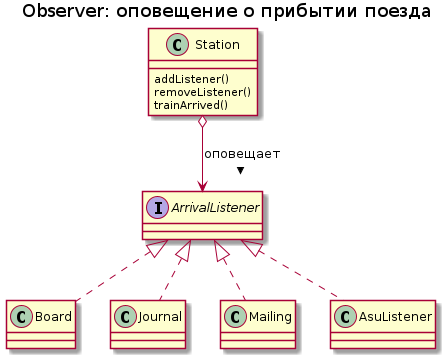

In [22]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка): _(Observer снял жесткую связанность: класс Station больше не знает о конкретных получателях. Новые проблемы: порядок уведомлений теперь зависит от порядка подписки (его нужно контролировать); ошибка в одном наблюдателе может прервать рассылку остальным; если подписчик забыл отписаться, он будет продолжать получать события, что может привести к утечке памяти.)_

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy |  |  |  |  |
| Factory Method |  |  |  |  |
| Observer |  |  |  |  |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** _(Нарушает Принцип открытости/закрытости (OCP). Strategy выносит алгоритмы в классы, Factory Method выносит создание в создателей, Observer выносит оповещение в подписчиков.)_
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** _(Factory Method — это паттерн, где создание делегируется подклассам (наследование). Статический метод — просто утилита в классе. Abstract Factory создает целые семейства связанных объектов.)_
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** _(Strategy — это выбор алгоритма (клиент сам выбирает, как считать). State — это изменение поведения объекта при изменении его внутреннего состояния (переходы происходят автоматически).)_
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** _(Если подписчик не отписывается (забыли вызвать removeListener), субъект хранит на него ссылку и не дает сборщику мусора его удалить. Нужно использовать слабые ссылки (WeakReference) или строго следить за отпиской.)_
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** _(Паттерн вреден, когда система простая и не планирует расширяться. Введение паттернов ради паттернов — это «преждевременное усложнение», которое делает код нечитаемым и тяжелым в поддержке без реальной пользы.)_

### 5.3 Три вывода по работе в целом

1.Паттерны нужны для того, чтобы изолировать изменения.
2. Паттерны всегда усложняют структуру кода, поэтому их нужно применять только при реальной необходимости.
3. Главный признак хорошего паттерна — старый код не меняется при добавлении новой функциональности.

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [ ]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = ""  #@param {type:"string"}
Группа_исполнителя = ""  #@param {type:"string"}
Номер_варианта = 1  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = False  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |